# iLQR compared with gradient descent

A finite-horizon control problem can also be solved by treating the input sequence $u_{0:T-1}$ as
free parameters and minimising the rolled-out cost $J(u)$ with a first-order optimiser such as
Adam. This is the *shooting* or *backpropagation-through-time* approach.

This notebook compares that approach with iLQR on the same pendulum swing-up as the
[previous example](simple_pendulum.ipynb). iLQR uses the problem's temporal structure: its
Riccati backward pass is a Newton-like step computed in $O(T)$. It typically needs far fewer
iterations than gradient descent and reaches a better optimum.

In [1]:
import time as timer

import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import optax

from diffilqrax.ilqr import ilqr_solver, ilqr_simulate
from diffilqrax.typs import System, ModelDims, iLQRParams, PendulumParams

jax.config.update("jax_enable_x64", True)

## The problem

The pendulum swing-up from the previous notebook:

In [2]:
DT, DAMPING, U_MAX, HORIZON = 0.05, 0.1, 3.0, 100
dims = ModelDims(n=2, m=1, horizon=HORIZON, dt=DT)


def dynamics(t, x, u, theta):
    """Euler step; x = [angle, angular velocity], angle 0 is hanging down"""
    acc = -theta.g / theta.l * jnp.sin(x[0]) - DAMPING * x[1] + u[0] / (theta.m * theta.l**2)
    return x + DT * jnp.stack([x[1], acc])


def cost(t, x, u, theta):
    """Small running cost on angle, velocity and torque, plus a smooth barrier at |u| = U_MAX"""
    barrier = jax.nn.softplus(5.0 * (u - U_MAX)) ** 2 + jax.nn.softplus(5.0 * (-u - U_MAX)) ** 2
    return 0.1 * (1.0 + jnp.cos(x[0])) + 0.01 * x[1] ** 2 + 0.01 * jnp.sum(u**2) + jnp.sum(barrier)


def costf(x, theta):
    """Be upright (angle ±pi) and still at the final time"""
    return 50.0 * (1.0 + jnp.cos(x[0])) + 5.0 * x[1] ** 2


model = System(cost, costf, dynamics, dims)
params = iLQRParams(x0=jnp.array([0.1, 0.0]), theta=PendulumParams(m=1.0, l=1.0, g=9.8))
Us_init = 0.5 * jr.normal(jr.PRNGKey(0), (HORIZON, 1))
time = jnp.arange(HORIZON + 1) * DT

## iLQR

We compile the solver once with `jax.jit` and then time a second call.

In [3]:
solve = jax.jit(lambda p, u: ilqr_solver(model, p, u, max_iter=300))
jax.block_until_ready(solve(params, Us_init))  # compile

start = timer.perf_counter()
(Xs_ilqr, Us_ilqr, _), J_ilqr, cost_log = jax.block_until_ready(solve(params, Us_init))
t_ilqr = timer.perf_counter() - start
iters_ilqr = int(jnp.sum(jnp.diff(cost_log) != 0)) + 1
print(f"iLQR: J = {float(J_ilqr):.4f} in {iters_ilqr} iterations, {t_ilqr*1e3:.0f} ms")

iLQR: J = 17.8970 in 184 iterations, 169 ms


## Gradient descent (Adam)

`ilqr_simulate` rolls out the dynamics and returns the total cost. It is differentiable with
respect to `Us`, so `jax.value_and_grad` gives $\nabla_u J$ by backpropagation through time.

In [4]:
def loss(Us):
    return ilqr_simulate(model, Us, params)[1]


optimiser = optax.adam(learning_rate=0.05)


@jax.jit
def adam_step(carry, _):
    Us, state = carry
    J, g = jax.value_and_grad(loss)(Us)
    updates, state = optimiser.update(g, state)
    return (optax.apply_updates(Us, updates), state), J


n_steps = 5000
run = jax.jit(lambda u: jax.lax.scan(adam_step, (u, optimiser.init(u)), None, length=n_steps))
jax.block_until_ready(run(Us_init))  # compile

start = timer.perf_counter()
(Us_gd, _), gd_log = jax.block_until_ready(run(Us_init))
t_gd = timer.perf_counter() - start
(Xs_gd, _), J_gd = ilqr_simulate(model, Us_gd, params)
print(f"Adam: J = {float(J_gd):.4f} after {n_steps} steps, {t_gd*1e3:.0f} ms")

Adam: J = 20.4651 after 5000 steps, 1943 ms


## Comparison

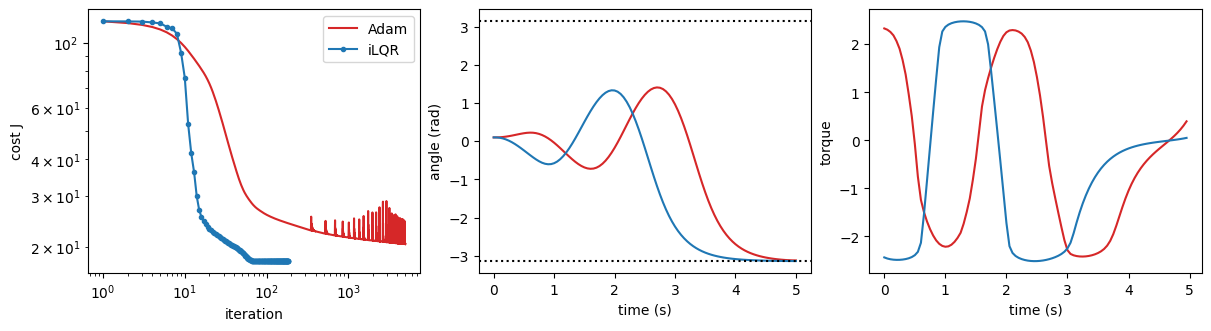

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), layout="constrained")
axes[0].loglog(jnp.arange(1, n_steps + 1), gd_log, c="C3", label="Adam")
axes[0].loglog(jnp.arange(1, iters_ilqr + 1), cost_log[:iters_ilqr], "o-", c="C0", ms=3, label="iLQR")
axes[0].set(xlabel="iteration", ylabel="cost J")
axes[0].legend()
axes[1].plot(time, Xs_gd[:, 0], c="C3", label="Adam")
axes[1].plot(time, Xs_ilqr[:, 0], c="C0", label="iLQR")
for s in (-1, 1):
    axes[1].axhline(s * jnp.pi, ls=":", c="k")
axes[1].set(xlabel="time (s)", ylabel="angle (rad)")
axes[2].plot(time[:-1], Us_gd[:, 0], c="C3")
axes[2].plot(time[:-1], Us_ilqr[:, 0], c="C0")
axes[2].set(xlabel="time (s)", ylabel="torque");

In [6]:
print(f"{'':6s}{'final cost':>12s}{'iterations':>12s}{'time (ms)':>12s}")
print(f"{'iLQR':6s}{float(J_ilqr):12.4f}{iters_ilqr:12d}{t_ilqr*1e3:12.0f}")
print(f"{'Adam':6s}{float(J_gd):12.4f}{n_steps:12d}{t_gd*1e3:12.0f}")

        final cost  iterations   time (ms)
iLQR       17.8970         184         169
Adam       20.4651        5000        1943


In this run, Adam also finds a swing-up, but it is a different and more expensive one. It stalls
at a higher cost and oscillates with the fixed learning rate. iLQR reaches a lower cost in far
fewer iterations and less wall time. Each iLQR iteration costs more than an Adam step, because it
needs a backward pass, a rollout and a line search, but each step uses curvature, whereas Adam
sees only the poorly conditioned gradient of a long rollout. On harder problems, such as longer
horizons or unstable dynamics, the gap usually widens, and gradient descent may not find the
swing-up at all.

## How to adapt

- **Your own problem:** both methods take the same `System`, so swap in your dynamics and cost to
  compare them on your task.
- **Tuning the baseline:** the Adam learning rate and step count are the key knobs. Too large a
  learning rate diverges on long horizons.
- **When gradient descent is preferable:** with non-smooth costs, or when $u$ comes from a policy
  network rather than a free sequence. Even then, iLQR solutions make good targets or warm starts.